# Práctica 5: Detección y caracterización de caras

Programa final de la práctica, con los prototipos que reaccionan a la información extraída de las caras:

- **Prototipo A** (pendiente): un modelo entrenado por nosotros para extraer información biométrica.
- **Prototipo B**: _Ceci n'est pas une pipe_, una pipa que se coge con la mano y se fuma.
- **Extra** (pendiente): parecido con famosos.

El detector facial se elige en [`face_detectors_comparative.ipynb`](face_detectors_comparative.ipynb).

## 1. Configuración

In [1]:
import time
from functools import lru_cache

import cv2
import mediapipe as mp
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw, ImageFont

from common.face_detectors import DETECTORS, largest_face
from common.models import model_bytes
from common.paths import ASSETS, PIPE_RESULTS

PIPE_RESULTS.mkdir(parents=True, exist_ok=True)

Se usa YuNet, el detector elegido en la [comparativa](face_detectors_comparative.ipynb#7-conclusiones), con el umbral que se ajustó allí:

In [2]:
face_detector = DETECTORS["yunet"]()
face_detector.threshold = 0.77
print(f"Detector facial: {face_detector.label} (umbral {face_detector.threshold:.2f})")

Detector facial: YuNet (umbral 0.77)


Funciones auxiliares para pegar una imagen con transparencia sobre otra y para pasar una imagen a MediaPipe:

In [3]:
def overlay(frame, rgba, x, y):
    height, width = rgba.shape[:2]
    x0, y0, x1, y1 = max(x, 0), max(y, 0), min(x + width, frame.shape[1]), min(y + height, frame.shape[0])
    if x1 <= x0 or y1 <= y0:
        return
    patch = rgba[y0 - y:y1 - y, x0 - x:x1 - x]
    alpha = patch[..., 3:] / 255
    frame[y0:y1, x0:x1] = (frame[y0:y1, x0:x1] * (1 - alpha) + patch[..., :3] * alpha).astype(np.uint8)


def to_mediapipe(bgr):
    return mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))

## 2. Prototipo A

_Pendiente._

## 3. Prototipo B: _Ceci n'est pas une pipe_

En _La trahison des images_ (1929), Magritte pinta una pipa y escribe debajo «Ceci n'est pas une pipe»: lo que vemos es la imagen de una pipa, no una pipa. Este prototipo lleva la idea a la webcam, con una pipa que tampoco es una pipa, pero que se puede coger y fumar:

1. La pipa flota en la imagen, con la leyenda del cuadro debajo.
2. Se coge haciendo una **pinza** con el pulgar y el índice, y sigue a la mano. Al abrir la pinza, se queda donde se ha soltado.
3. Mientras se sujeta, la boquilla apunta a la **boca**.
4. Al llevar la boquilla a la boca, la cazoleta **se enciende** y se **inhala**: los pulmones se llenan poco a poco.
5. El humo sale siempre que se **abre la boca**, esté la pipa donde esté: un chorro de humo y, cada poco tiempo, una **burbuja de humo**. Al cerrar la boca, el humo que queda se aguanta en los pulmones, hasta que se vuelva a abrir.

Se utilizan tres modelos: el detector facial elegido (YuNet), para la posición de la boca y el tamaño de la cara; el detector de manos de MediaPipe, para la pinza; y el detector de puntos faciales de MediaPipe, para saber si la boca está abierta.

### 3.1 La pipa

La pipa es una imagen PNG con transparencia ([`assets/pipe.png`](assets/pipe.png)). Para colocarla, se necesitan tres de sus puntos, en píxeles de la imagen: el agarre (`GRIP`), la boquilla (`TIP`) y el hueco de la cazoleta (`BOWL`). Para usar otra pipa, basta con cambiar el PNG y estos tres puntos.

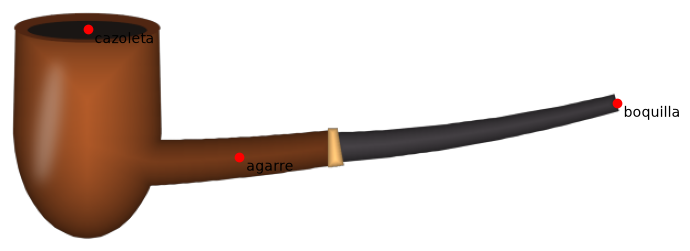

In [4]:
PIPE = cv2.imread(str(ASSETS / "pipe.png"), cv2.IMREAD_UNCHANGED)
GRIP, TIP, BOWL = np.array([208, 133]), np.array([551, 84]), np.array([70, 17])

plt.figure(figsize=(8, 3))
plt.imshow(cv2.cvtColor(PIPE, cv2.COLOR_BGRA2RGBA))
for name, point in {"agarre": GRIP, "boquilla": TIP, "cazoleta": BOWL}.items():
    plt.scatter(*point, color="red")
    plt.annotate(name, point, xytext=(5, -10), textcoords="offset points")
plt.axis("off")
plt.show()

La clase `Pipe` coloca la pipa con una transformación afín (escala, giro y reflejo horizontal):

- `grip` es la posición del agarre en el fotograma, y `length` el largo de la pipa, que se ajusta al ancho de la cara (`PIPE_TO_FACE` veces).
- `point` devuelve la posición en el fotograma de un punto de la pipa.
- `aim` gira la pipa para que la boquilla apunte a la boca, y la refleja si la boca está al otro lado. El giro se limita a `MAX_TILT` grados.
- `straighten` la devuelve poco a poco a la horizontal cuando se suelta.
- `draw` solo transforma el trozo del fotograma que ocupa la pipa.

In [5]:
PIPE_TO_FACE = 1.3
MAX_TILT = 40


class Pipe:
    def __init__(self, grip, length):
        self.grip = np.array(grip, np.float32)
        self.length = length
        self.angle = 0.0
        self.flipped = False
        self.held = False

    @property
    def scale(self):
        return self.length / PIPE.shape[1]

    def transform(self):
        cos, sin = np.cos(np.radians(self.angle)), np.sin(np.radians(self.angle))
        flip = np.diag([-1.0 if self.flipped else 1.0, 1.0])
        matrix = self.scale * np.array([[cos, -sin], [sin, cos]]) @ flip
        return matrix, self.grip - matrix @ GRIP

    def point(self, point):
        matrix, offset = self.transform()
        return matrix @ point + offset

    def aim(self, target, dt):
        direction = target - self.grip
        if abs(direction[0]) > 0.15 * self.length:
            self.flipped = direction[0] < 0
        stem = (TIP - GRIP) * [-1 if self.flipped else 1, 1]
        angle = np.degrees(np.arctan2(direction[1], direction[0]) - np.arctan2(stem[1], stem[0]))
        angle = np.clip((angle + 180) % 360 - 180, -MAX_TILT, MAX_TILT)
        self.angle += (angle - self.angle) * min(1.0, 8 * dt)

    def straighten(self, dt):
        self.angle -= self.angle * min(1.0, 3 * dt)

    def draw(self, frame):
        matrix, offset = self.transform()
        height, width = PIPE.shape[:2]
        corners = np.array([[0, 0], [width, 0], [0, height], [width, height]]) @ matrix.T + offset
        x0, y0 = np.floor(corners.min(axis=0)).astype(int)
        x1, y1 = np.ceil(corners.max(axis=0)).astype(int)
        warp = np.hstack([matrix, (offset - [x0, y0])[:, None]])
        overlay(frame, cv2.warpAffine(PIPE, warp, (x1 - x0, y1 - y0)), x0, y0)

### 3.2 La mano

El detector de manos de MediaPipe devuelve 21 puntos por mano. La pinza se mide con la distancia entre las puntas del pulgar y del índice, dividida entre el tamaño de la mano (de la muñeca a la base del dedo corazón), para que no dependa de la distancia a la cámara.

Para que la pipa no se suelte y se vuelva a coger por el temblor de los puntos, se usan dos umbrales: se coge al cerrar la pinza por debajo de `GRAB_RATIO` cerca del agarre, y se suelta al abrirla por encima de `RELEASE_RATIO` o al perder la mano durante `LOST_TIME` segundos.

In [6]:
WRIST, THUMB_TIP, INDEX_TIP, MIDDLE_BASE = 0, 4, 8, 9
GRAB_RATIO = 0.35
RELEASE_RATIO = 0.55
GRAB_REACH = 0.6
LOST_TIME = 0.4


class Hands:
    def __init__(self):
        options = mp.tasks.vision.HandLandmarkerOptions(
            base_options=mp.tasks.BaseOptions(model_asset_buffer=model_bytes("hand_landmarker.task")),
            running_mode=mp.tasks.vision.RunningMode.VIDEO, num_hands=2)
        self.model = mp.tasks.vision.HandLandmarker.create_from_options(options)
        self.timestamp = 0

    def __call__(self, bgr):
        self.timestamp = max(self.timestamp + 1, int(time.perf_counter() * 1000))
        height, width = bgr.shape[:2]
        result = self.model.detect_for_video(to_mediapipe(bgr), self.timestamp)
        return [np.array([(p.x * width, p.y * height) for p in hand]) for hand in result.hand_landmarks]


def pinch(hand):
    size = np.linalg.norm(hand[WRIST] - hand[MIDDLE_BASE])
    ratio = np.linalg.norm(hand[THUMB_TIP] - hand[INDEX_TIP]) / size
    return ratio, (hand[THUMB_TIP] + hand[INDEX_TIP]) / 2

### 3.3 La boca abierta

YuNet solo devuelve las comisuras, que no indican si la boca está abierta. Para eso se usa el detector de puntos faciales de MediaPipe (478 puntos) sobre el recorte de la cara de YuNet. La apertura es la distancia entre los labios dividida entre el ancho de la boca: de 0.01 a 0.06 con la boca cerrada, de 0.13 a 0.20 al sonreír y de 0.45 en adelante con la boca abierta. Se considera abierta por encima de `MOUTH_OPEN` = 0.1, para que baste con entreabrirla.

Si la mano tapa la cara y no se encuentran los labios, devuelve `None` y se mantiene el último estado.

In [7]:
UPPER_LIP, LOWER_LIP, LEFT_CORNER, RIGHT_CORNER = 13, 14, 61, 291
MOUTH_OPEN = 0.1
CROP_MARGIN = 0.3


class MouthOpening:
    def __init__(self):
        options = mp.tasks.vision.FaceLandmarkerOptions(
            base_options=mp.tasks.BaseOptions(model_asset_buffer=model_bytes("face_landmarker.task")), num_faces=1)
        self.model = mp.tasks.vision.FaceLandmarker.create_from_options(options)

    def __call__(self, bgr, face):
        crop = face_crop(bgr, face.box)
        result = self.model.detect(to_mediapipe(crop))
        if not result.face_landmarks:
            return None
        points = np.array([(p.x * crop.shape[1], p.y * crop.shape[0]) for p in result.face_landmarks[0]])
        gap = np.linalg.norm(points[UPPER_LIP] - points[LOWER_LIP])
        return gap / np.linalg.norm(points[LEFT_CORNER] - points[RIGHT_CORNER])


def face_crop(bgr, box):
    x1, y1, x2, y2 = box
    margin = CROP_MARGIN * (x2 - x1)
    x1, y1 = int(max(0, x1 - margin)), int(max(0, y1 - margin))
    x2, y2 = int(min(bgr.shape[1], x2 + margin)), int(min(bgr.shape[0], y2 + margin))
    return np.ascontiguousarray(bgr[y1:y2, x1:x2])

### 3.4 El humo

El humo es un sistema de partículas. Cada una tiene posición, velocidad, edad, duración, tamaño y densidad:

- `emit` crea partículas en un punto (la cazoleta o la boca), en una dirección con cierta dispersión. Se usa para el chorro de humo y para las burbujas, que son partículas grandes y densas.
- `update` las mueve: las frena, las hace subir y las desplaza de lado a lado, como el humo real.
- `draw` dibuja cada partícula como una mancha gaussiana que crece y se aclara con la edad. Para que sea rápido, se agrupan por tamaño y cada grupo se desenfoca una sola vez. La opacidad es $1 - e^{-\text{densidad}}$, así que el humo se espesa donde se acumula.

In [8]:
X, Y, VX, VY, AGE, LIFE, SIZE, DENSITY = range(8)
SMOKE_COLOR = np.array([214, 214, 208], np.float32)
BLUR_SIZES = np.array([2, 4, 8, 16], np.float32)
MAX_PARTICLES = 900


class Smoke:
    def __init__(self):
        self.particles = np.zeros((0, 8), np.float32)
        self.rng = np.random.default_rng(0)

    def emit(self, origin, count, velocity, spread, size, life, density):
        angle = np.arctan2(velocity[1], velocity[0]) + self.rng.normal(0, np.radians(spread), count)
        speed = np.hypot(*velocity) * self.rng.uniform(0.6, 1.2, count)
        new = np.column_stack([np.full(count, origin[0]), np.full(count, origin[1]), np.cos(angle) * speed,
                               np.sin(angle) * speed, np.zeros(count), life * self.rng.uniform(0.7, 1.3, count),
                               size * self.rng.uniform(0.7, 1.3, count), np.full(count, density)])
        self.particles = np.vstack([self.particles, new])[-MAX_PARTICLES:]

    def update(self, dt, rise, wind):
        p = self.particles
        p[:, AGE] += dt
        p = p[p[:, AGE] < p[:, LIFE]]
        p[:, [VX, VY]] *= 0.97 ** (dt * 60)
        p[:, VY] -= rise * dt
        p[:, VX] += np.sin(3 * p[:, AGE] + p[:, X] / 50) * wind * dt
        p[:, [X, Y]] += p[:, [VX, VY]] * dt
        self.particles = p

    def draw(self, frame):
        height, width = frame.shape[:2]
        layer = np.zeros((height // 2, width // 2), np.float32)
        p = self.particles
        t = p[:, AGE] / p[:, LIFE]
        density = p[:, DENSITY] * (1 - t) ** 1.5 * np.minimum(1, 4 * p[:, AGE])
        size = np.maximum(1, p[:, SIZE] * (1 + 3.5 * t) / 2)
        x, y = (p[:, X] / 2).astype(int), (p[:, Y] / 2).astype(int)
        inside = (x >= 0) & (x < layer.shape[1]) & (y >= 0) & (y < layer.shape[0])
        group = np.abs(np.log(size[:, None] / BLUR_SIZES)).argmin(axis=1)
        for i, blur in enumerate(BLUR_SIZES):
            selected = inside & (group == i)
            points = np.zeros_like(layer)
            np.add.at(points, (y[selected], x[selected]), density[selected] * 2 * np.pi * blur ** 2)
            layer += cv2.GaussianBlur(points, (0, 0), float(blur))
        alpha = 1 - np.exp(-cv2.resize(layer, (width, height)))[..., None]
        frame[:] = (frame + (SMOKE_COLOR - frame) * alpha).astype(np.uint8)

### 3.5 La brasa y la leyenda

La brasa es una elipse naranja en el hueco de la cazoleta, más visible cuanto más encendida está la pipa. La leyenda se escribe con Pillow y la fuente Segoe Script, porque OpenCV no tiene fuentes manuscritas ni puede escribir tildes. Cada texto se genera una sola vez (`lru_cache`).

In [9]:
EMBER_COLOR = (40, 140, 255)
CAPTION = "Ceci n'est pas une pipe."
CAPTION_SMOKE = "Ceci n'est pas de la fumée."


def draw_ember(frame, pipe, level):
    if level < 0.05:
        return
    ember = frame.copy()
    center = tuple(pipe.point(BOWL + [0, 4]).astype(int))
    axes = (int(52 * pipe.scale), max(1, int(7 * pipe.scale)))
    cv2.ellipse(ember, center, axes, pipe.angle, 0, 360, EMBER_COLOR, -1, cv2.LINE_AA)
    cv2.addWeighted(ember, level, frame, 1 - level, 0, frame)


@lru_cache(maxsize=4)
def caption_image(text, width):
    font = ImageFont.truetype("segoesc.ttf", width // 24)
    left, top, right, bottom = font.getbbox(text)
    image = Image.new("RGBA", (right - left + 20, bottom - top + 20))
    ImageDraw.Draw(image).text((10 - left, 10 - top), text, font=font, fill=(26, 22, 20), stroke_width=3,
                               stroke_fill=(236, 230, 218))
    return cv2.cvtColor(np.array(image), cv2.COLOR_RGBA2BGRA)


def draw_caption(frame, text):
    image = caption_image(text, frame.shape[1])
    overlay(frame, image, (frame.shape[1] - image.shape[1]) // 2, frame.shape[0] - image.shape[0] - 5)

### 3.6 La escena

`PipeScene` une todas las piezas. En cada fotograma, `update` recibe la cara más grande, la apertura de la boca y las manos, y:

1. **`see_face`**: ajusta el tamaño de la pipa a la cara y guarda si la boca está abierta. Si se deja de ver la cara, se usa la última durante `FACE_MEMORY` segundos, porque la mano que sujeta la pipa tapa parte de la cara.
2. **`move_pipe`**: coge, mueve o suelta la pipa, y la apunta a la boca o la endereza.
3. **`breathe`**: si la boquilla está a menos de `MOUTH_RADIUS` anchos de cara de la boca, se fuma: la brasa se aviva y los pulmones se llenan en `INHALE_TIME` segundos. Si no, la brasa se apaga en `EMBER_FADE` segundos.
4. **`blow`**: con la boca abierta y humo en los pulmones, sale un chorro de humo hacia el lado contrario a la pipa, y los pulmones se vacían en `EXHALE_TIME` segundos. Cada `BUBBLE_EVERY` segundos sale también una burbuja, que gasta `BUBBLE_COST` de los pulmones.

In [10]:
MOUTH_RADIUS = 0.25
INHALE_TIME = 4.0
EXHALE_TIME = 8.0
BUBBLE_EVERY = 0.4
BUBBLE_COST = 0.06
EMBER_FADE = 8.0
FACE_MEMORY = 0.5


class PipeScene:
    def __init__(self, shape):
        self.height, self.width = shape[:2]
        self.reset()

    def reset(self):
        self.pipe = Pipe((0.3 * self.width, 0.68 * self.height), 0.3 * self.width)
        self.smoke = Smoke()
        self.face, self.face_age = None, np.inf
        self.lungs = self.ember = self.lost = self.next_bubble = 0.0
        self.mouth_open = self.smoking = self.exhaling = False

    def update(self, face, openness, hands, dt):
        self.see_face(face, openness, dt)
        self.move_pipe(hands, dt)
        self.breathe(dt)
        self.smoke.update(dt, rise=0.23 * self.pipe.length, wind=0.37 * self.pipe.length)

    def see_face(self, face, openness, dt):
        if face is not None:
            self.face, self.face_age = face, 0.0
            self.pipe.length += (PIPE_TO_FACE * face.width - self.pipe.length) * min(1.0, 4 * dt)
        else:
            self.face_age += dt
            self.face = self.face if self.face_age < FACE_MEMORY else None
        if openness is not None:
            self.mouth_open = openness > MOUTH_OPEN

    def move_pipe(self, hands, dt):
        self.grab(hands, dt)
        if self.pipe.held and self.face is not None:
            self.pipe.aim(np.array(self.face.mouth), dt)
        elif not self.pipe.held:
            self.pipe.straighten(dt)

    def grab(self, hands, dt):
        pipe = self.pipe
        pinches = [pinch(hand) for hand in hands]
        if not pipe.held:
            for ratio, point in pinches:
                if ratio < GRAB_RATIO and np.linalg.norm(point - pipe.grip) < GRAB_REACH * pipe.length:
                    pipe.held, pipe.grip, self.lost = True, point.astype(np.float32), 0.0
            return
        nearby = [(ratio, point) for ratio, point in pinches if np.linalg.norm(point - pipe.grip) < pipe.length]
        if not nearby:
            self.lost += dt
            pipe.held = self.lost < LOST_TIME
            return
        ratio, point = min(nearby, key=lambda pinch: np.linalg.norm(pinch[1] - pipe.grip))
        self.lost = 0.0
        pipe.held = ratio < RELEASE_RATIO
        pipe.grip += (point - pipe.grip) * (1 - np.exp(-20 * dt))

    def breathe(self, dt):
        self.smoking = self.exhaling = False
        if self.face is not None:
            mouth = np.array(self.face.mouth)
            self.smoking = np.linalg.norm(self.pipe.point(TIP) - mouth) < MOUTH_RADIUS * self.face.width
            self.exhaling = self.mouth_open and self.lungs > 0

        if self.smoking and not self.exhaling:
            self.lungs = min(1.0, self.lungs + dt / INHALE_TIME)
            self.ember = min(1.0, self.ember + 1.5 * dt)
        else:
            self.ember = max(0.0, self.ember - dt / EMBER_FADE)

        length = self.pipe.length
        count = self.smoke.rng.poisson((30 + 40 * self.smoking) * self.ember * dt)
        self.smoke.emit(self.pipe.point(BOWL), count, (0, -0.23 * length), 12, 0.017 * length, 2.8, 0.3)
        if self.exhaling:
            self.blow(mouth, dt)
        else:
            self.next_bubble = 0.0

    def blow(self, mouth, dt):
        width = self.face.width
        side = 1 if self.pipe.point(BOWL)[0] < mouth[0] else -1
        velocity = np.array([side, -0.35]) * 2.2 * width
        self.lungs = max(0.0, self.lungs - dt / EXHALE_TIME)
        count = self.smoke.rng.poisson((60 * self.lungs + 10) * dt)
        self.smoke.emit(mouth, count, velocity, 16, 0.05 * width, 2.2, 0.3)
        self.next_bubble -= dt
        if self.next_bubble <= 0 and self.lungs >= BUBBLE_COST:
            self.smoke.emit(mouth, 1, 0.6 * velocity, 0, 0.25 * width, 2.5, 1.0)
            self.lungs -= BUBBLE_COST
            self.next_bubble = BUBBLE_EVERY

    def draw(self, frame):
        self.pipe.draw(frame)
        draw_ember(frame, self.pipe, self.ember)
        self.smoke.draw(frame)
        draw_caption(frame, CAPTION_SMOKE if self.exhaling else CAPTION)

### 3.7 Prototipo con la webcam

La imagen se muestra en modo espejo, para que la pipa se mueva hacia el mismo lado que la mano. Controles:

| Tecla | Acción |
|---|---|
| Pinza sobre la pipa | Cogerla (abrir la pinza la suelta) |
| **r** | Devolver la pipa a su sitio |
| **v** | Empezar o parar la grabación, que se guarda en `results/pipe/` |
| **ESC** | Salir |

Solo se ejecuta si `RUN_PIPE = True`.

In [11]:
RUN_PIPE = True


def start_recording(frame):
    path = PIPE_RESULTS / f"pipe_{time.strftime('%Y%m%d_%H%M%S')}.mp4"
    print("Grabando en", path)
    return cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*"mp4v"), 30, (frame.shape[1], frame.shape[0]))


def run_pipe(camera=0):
    hands, mouth_opening = Hands(), MouthOpening()
    capture = cv2.VideoCapture(camera)
    scene, writer = None, None
    previous = time.perf_counter()
    while True:
        ok, frame = capture.read()
        if not ok:
            break
        frame = cv2.flip(frame, 1)
        now = time.perf_counter()
        dt, previous = min(now - previous, 0.1), now
        scene = scene or PipeScene(frame.shape)

        face = largest_face(face_detector(frame))
        openness = mouth_opening(frame, face) if face is not None else None
        scene.update(face, openness, hands(frame), dt)
        scene.draw(frame)

        if writer is not None:
            writer.write(frame)
            cv2.circle(frame, (frame.shape[1] - 20, 20), 8, (0, 0, 255), -1)
        cv2.imshow("Ceci n'est pas une pipe", frame)

        key = cv2.waitKey(1) & 0xFF
        if key == 27:
            break
        elif key == ord("r"):
            scene.reset()
        elif key == ord("v"):
            writer = start_recording(frame) if writer is None else writer.release()
    if writer is not None:
        writer.release()
    capture.release()
    cv2.destroyAllWindows()


if RUN_PIPE:
    run_pipe()

## 4. Extra: parecido con famosos

_Pendiente._